# HypeCheck — test the crowd, not just a tweet
**Veritas AI International High School Hackathon 2026 · AI + Finance**
**Team:** Nathaniel Wong · Aaden Yick · Alastair Chu — Malvern College Hong Kong

**Our user:** a trader who sees many public posts about one memecoin and wonders whether the wording and crowd sentiment deserve forecasting trust. **Input:** a batch of public posts. **Output:** estimated sample sentiment, a next-day direction estimate, and the evidence against simple baselines.

**Bottom line:** this experiment does not demonstrate a forecasting edge. We report that rather than turn a weak model into trading advice.

**Runtime → Run all.** Section 5 visibly trains Model 1; Section 8 tests balanced training and character-based wording features. Section 9 runs the trained batch forecast and offers an optional interactive app. Source setup is collapsed; data loading stays short.

**Live demo:** paste a tweet at https://adeviwon.github.io/hypecheck/live.html and the trained wording + coin model runs in the browser, with its own held-out scores shown beside the forecast. The complete model, including the frozen sentiment block, runs here.

**Our investigation:** inspect real posts → establish simple baselines → train a word-based model → examine its mistakes → test later dates and new coins → test balanced training and character features → explain the predictions and findings. All price outcomes are historical market observations.

*This project is a prototype and is not financial advice. No complete or live X feed, causal impact or trading skill is claimed. This reused archive is exploratory, not independent confirmation.*

In [1]:
#@title Automatic environment setup
import sys,subprocess,json,hashlib,urllib.request,contextlib,io
from pathlib import Path
IN_COLAB="google.colab" in sys.modules
if IN_COLAB:
    pins=["numpy==2.5.4","pandas==3.1.1","pyarrow==26.0.1","scikit-learn==1.9.1","requests==2.34.2","ipython==9.18.1","ipywidgets==8.1.9","transformers==5.23.0","safetensors==0.8.0"]
    subprocess.run([sys.executable,"-m","pip","install","-q",*pins],check=True)
print("Environment ready; actual Google Colab runtime:",IN_COLAB)

Environment ready; actual Google Colab runtime: False


In [2]:
SETUP_REV='2ce94ac955100ec37968fdfa404e3ae7af8e430b'
BOOTSTRAP={'colab_setup.py': '48e912fec0f69329b2ed93ef5da6cca4890ec191fa6e84367eece7be2a246cb4', 'notebook_support.py': 'e5dd57e29724851b18e5bd2ebfb9b226b4bb5a72be36b4144a51503ab2e01e70'}
SOURCE_REV='de1b2180a582d04a8d43715e01c971596929778b'
SOURCE_FILES={'sample_pipeline.py': '268751cd13f2c47017a96cfb24e5d26ddedd2318748596823bf4be880bdd9605', 'crowd_snapshot.py': 'a32105c5fff454b15619a718a35997da441580866b0054e57e10861115cb134f', 'crowd_app.py': '9b0c527cd800ae3caee7275c0a63fb72c7284d3a3bacc40afdb680e6b40ce081', 'test_sample_pipeline.py': 'ac9c345ed02a4803d428119640b915b5ba410c3ddeb23a3dba398d570ee4cd4a', 'test_crowd_snapshot.py': '79cb9c9983d72e729bf069dc6d253125778d9e2e60ba774499c73ccf7caddb4d', 'test_crowd_app.py': 'ccf94fbc82dff1cd9194eb945db78b8498e433cdb8f93696339a77ce6bb177f1', 'judge_tables.py': '90da7f2881172eb1a0701ad2ee0df7c92221c58d40adf8df6048077ca9d6701f', 'test_judge_tables.py': 'd72143a72278f6d05616380aba5b4af27bb4d9b10d7bbf3881170e0422645058'}
for name,(revision,expected) in {**{n:(SETUP_REV,h) for n,h in BOOTSTRAP.items()},**{n:(SOURCE_REV,h) for n,h in SOURCE_FILES.items()}}.items():
    url=f"https://raw.githubusercontent.com/adeviwon/hypecheck/{revision}/{name}"
    with urllib.request.urlopen(url,timeout=60) as response:payload=response.read()
    if hashlib.sha256(payload).hexdigest()!=expected:raise ValueError("Changed verified file: "+name)
    Path(name).write_bytes(payload)
from colab_setup import prepare
prepare()
import numpy as np,pandas as pd
from IPython.display import display,HTML
from notebook_support import table,accuracy_chart
from sample_pipeline import *
from judge_tables import *
print("Pinned sources and actual market inputs verified; no downloaded forecasts.")

Verified source and market data. Sentiment: verified cache
Pinned sources and actual market inputs verified; no downloaded forecasts.


## 1. Load the data
Real original public X posts and actual daily Binance prices. Frozen FinTwitBERT estimates language sentiment; next-day labels come from the **actual market**, not the sentiment model. The downstream forecast models are trained during this run. Transformers are **not fine-tuned**.

In [3]:
frame,train,later,unseen=dataset()
print(f"Training: {len(train):,} snapshots; later-time test: {len(later):,}; unseen-coin test: {len(unseen):,}.")

Training: 991 snapshots; later-time test: 155; unseen-coin test: 99.


## 2. Look at the data first
We inspect real posts and their actual later market outcomes before fitting. Each row is a same-coin batch observed by a particular UTC cutoff, using the preceding 24 hours. Several snapshots can share one coin-day outcome, so each coin-day gets total weight one. Sentiment describes this supplied archive sample, not all of X. **Bullish language** and **bearish language** are average AI language scores, displayed as percentages—not the probability that the coin will rise or fall. **Actual next-day result** is measured from market prices, not predicted.

In [4]:
examples=examples_table(train)
table(examples.drop(columns=["Example wording"]),"Post batches, language scores and actual next-day results")
table(examples[["Forecast day (UTC)","Coin","Example wording"]],"Example public wording, kept separate so the data table stays readable")
from IPython.display import Markdown
display(Markdown("**What these examples show:** "+examples_findings(train.head(5))))
print("Established training coins:",BASE_COINS)
print("Excluded from supervised training:",NEW_COINS)

Established training coins: ('DOGE', 'SHIB', 'PEPE', 'BONK', 'FLOKI')
Excluded from supervised training: ('WIF', 'TRUMP', 'NEIRO', 'PENGU', 'PNUT', 'TURBO', 'BOME', 'MEME')


Snapshot time (UTC),Forecast day (UTC),Coin,Posts,Bullish language,Bearish language,Actual next-day result
"22 Mar 2024, 06:29",23 Mar 2024,DOGE,1,99.8%,0.0%,Rose (+5.86%)
"22 Mar 2024, 10:29",23 Mar 2024,DOGE,2,98.7%,1.2%,Rose (+5.86%)
"22 Mar 2024, 07:19",23 Mar 2024,FLOKI,1,86.4%,6.5%,Rose (+0.87%)
"31 Mar 2024, 12:02",01 Apr 2024,DOGE,1,75.9%,22.5%,Fell (-6.80%)
"31 Mar 2024, 15:02",01 Apr 2024,DOGE,2,72.0%,26.5%,Fell (-6.80%)


Forecast day (UTC),Coin,Example wording
23 Mar 2024,DOGE,$doge legit best looking major by a mile atm imo
23 Mar 2024,DOGE,$doge legit best looking major by a mile atm imo Bagged some Being honest here. I think $doge gonna pull numbers over the coming 3/4 week…
23 Mar 2024,FLOKI,The doge of this cycle should go for the next round anytime now IMO. After consolidation comes continuation. Invalidation below the horiz…
01 Apr 2024,DOGE,$DOGE 12H away from highest weekly close in 123 weeks Probably nothing
01 Apr 2024,DOGE,$DOGE 12H away from highest weekly close in 123 weeks Probably nothing $DOGE to 0.45 real quik 🔮 crystal Ball says


**What these examples show:** For the first DOGE snapshot, the language model gave an average bullish score of 99.8% across 1 post(s). The coin rose (+5.86%) on 23 Mar 2024. This bullish score describes the wording: it is NOT the probability that the price will rise. Another DOGE snapshot scored 75.9% bullish, but the coin fell (-6.80%) the next day. Bullish language and a rising market are different outcomes. Rows for the same coin and forecast day can contain overlapping posts; they are not independent trading examples.

## 3. Split into training and test sets
We run a stratified random 80/20 split with random_state=42 as a **diagnostic** on historical training data, but do not use its score as forecasting evidence: related snapshots and market dates can appear on both sides.

The primary financial test instead uses earlier calendar dates for training and the final 20% of the price calendar for testing, with a purge. The later-time set uses established coins; the other set uses coins excluded from training. Multi-coin posts mentioning excluded assets are removed from the established training cohort. This is new-to-training data, **not independent confirmation**: the archive was explored before.

In [5]:
from sklearn.model_selection import train_test_split
random_train,random_test=train_test_split(train,test_size=.2,stratify=train.actual_up,random_state=42)
table(pd.DataFrame([{ "Purpose":name,"Post batches":len(d),"Distinct coin-days":len(d[["date","coin"]].drop_duplicates()),"Dates with data":d.date.nunique(),"First forecast day":d.date.min().strftime("%d %b %Y"),"Last forecast day":d.date.max().strftime("%d %b %Y")} for name,d in [("Training",train),("Later dates",later),("Unseen coins",unseen)]]))
assert train.date.max()+pd.Timedelta(days=1)<min(later.date.min(),unseen.date.min())
print("Random diagnostic shared dates:",len(set(random_train.date)&set(random_test.date)))

Random diagnostic shared dates: 112


Purpose,Post batches,Distinct coin-days,Dates with data,First forecast day,Last forecast day
Training,991,556,334,23 Mar 2024,02 Dec 2025
Later dates,155,127,91,21 Apr 2026,20 Oct 2026
Unseen coins,99,77,57,23 Apr 2026,03 Oct 2026


## 4. Baselines: simple rules before AI
We compare the AI models with always-up, training majority/prevalence, coin-only and the previous **completed** UTC-day direction at the snapshot cutoff. No unfinished-day close is allowed.

Report accuracy, precision and recall for UP, confusion matrices and **Brier error** (probability error; lower is better). **Correct directions** means how often the forecast matched the market. **UP calls that were right** is precision; **rising days caught** is recall. These answer different questions. Methods use identical rows and coin-day weights. A high accuracy alone does not establish forecasting value.

In [6]:
from sklearn.linear_model import LogisticRegression
coin_encoder=encoder(coin_only=True)
coin_model=LogisticRegression(max_iter=1000).fit(coin_encoder.fit_transform(train),train.actual_up,sample_weight=weight(train))
base_models={"Coin only":(coin_encoder,coin_model)}
for label,part in [("Later dates",later),("Unseen coins",unseen)]:
    scores,_=evaluate(base_models,train,part)
    table(scores_table(scores),label)
    display(Markdown("**Baseline finding:** "+label+" — the coin-only rule was correct "+format(scores["Coin only"]["accuracy"],".2%")+" of the time. The post-based model needs to improve on this, not just produce convincing-looking probabilities."))

Model / rule,Correct directions,UP calls that were right,Rising days caught,Probability error ↓,Distinct coin-days
Coin-only baseline,51.18%,52.00%,40.62%,0.2532,127
Always predict a rise,50.39%,50.39%,100.00%,0.4961,127
Always predict the training majority,49.61%,No UP calls,0.00%,0.5039,127
Training-frequency probability,49.61%,No UP calls,0.00%,0.2503,127
Copy the last completed day,47.24%,47.69%,48.44%,0.5276,127


**Baseline finding:** Later dates — the coin-only rule was correct 51.18% of the time. The post-based model needs to improve on this, not just produce convincing-looking probabilities.

Model / rule,Correct directions,UP calls that were right,Rising days caught,Probability error ↓,Distinct coin-days
Coin-only baseline,55.84%,No UP calls,0.00%,0.2484,77
Always predict a rise,44.16%,44.16%,100.00%,0.5584,77
Always predict the training majority,55.84%,No UP calls,0.00%,0.4416,77
Training-frequency probability,55.84%,No UP calls,0.00%,0.2487,77
Copy the last completed day,55.84%,50.00%,61.76%,0.4416,77


**Baseline finding:** Unseen coins — the coin-only rule was correct 55.84% of the time. The post-based model needs to improve on this, not just produce convincing-looking probabilities.

## 5. Model 1: TF-IDF + logistic regression
We turn word usage into numerical features with TF-IDF, then fit logistic regression to actual price direction. Our fixed extra features represent estimated batch sentiment and coin identity; they remain unchanged between Model 1 and balanced Model 2. TF-IDF and scaling fit only training data. The label is whether the next complete UTC day closes above its open.

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
vec=TfidfVectorizer()
word_encoder=ColumnTransformer([("text",vec,"text"),("numeric",StandardScaler(),SOCIAL),("coin",OneHotEncoder(handle_unknown="ignore"),["coin"])])
X_train=word_encoder.fit_transform(train)
model1=LogisticRegression(max_iter=1000)
model1.fit(X_train,train.actual_up,sample_weight=weight(train))
models={"Model 1":(word_encoder,model1),**base_models}
score1,pred1=evaluate(models,train,later)
table(scores_table(score1),"Model 1 on later dates")
table(confusion_table(score1["Model 1"]),"Where Model 1 was right or wrong; weighted coin-day equivalents, not raw post counts")
display(Markdown("**What this result means:** "+model_findings(score1)))

Model / rule,Correct directions,UP calls that were right,Rising days caught,Probability error ↓,Distinct coin-days
Model 1 — word-based,36.09%,37.35%,39.58%,0.2766,127
Coin-only baseline,51.18%,52.00%,40.62%,0.2532,127
Always predict a rise,50.39%,50.39%,100.00%,0.4961,127
Always predict the training majority,49.61%,No UP calls,0.00%,0.5039,127
Training-frequency probability,49.61%,No UP calls,0.00%,0.2503,127
Copy the last completed day,47.24%,47.69%,48.44%,0.5276,127


What actually happened,Model predicted no rise,Model predicted a rise
Did not rise,20.5,42.5
Rose,38.7,25.3


**What this result means:** Model 1 — word-based predicted 36.09% of directions correctly, compared with 51.18% for the coin-only baseline. Of its UP calls, 37.35% were correct; it caught 39.58% of actual rising days. These are coin-day-weighted rates, not counts of independent trades. It did not beat the no-text baseline.

## 6. Where Model 1 goes wrong
We inspect five actual held-out errors. **Missed a rise** means the model predicted no rise but the price rose. **Predicted a rise that did not happen** means it made a false UP call. A missed UP and a false-UP forecast are different mistakes. Neither has a universal financial cost: losses depend on returns, fees and execution. These are errors, not fabricated successful demonstrations.

In [8]:
def inspect_errors(part,prep,model,title):
    p=model.predict_proba(prep.transform(part))[:,1]
    bad=part[((p>=.5)!=part.actual_up)].copy()
    bad["estimated_up"]=p[((p>=.5)!=part.actual_up)]
    bad["error_type"]=np.where(bad.actual_up.eq(1),"Missed UP","False UP")
    bad["estimated_language"]=np.where(bad.bullish>bad.bearish,"More bullish","More bearish/neutral")
    saved=export(prep,model)
    def reasons(row):
        explanation=infer(saved,row.to_dict())
        key="toward_up" if row.estimated_up>=.5 else "toward_down"
        return ", ".join(x["word"] for x in explanation[key][:3])
    shown=bad.head(5).copy();shown["actual_word_reasons"]=shown.apply(reasons,axis=1)
    table(errors_table(shown),title)
    table(bad.groupby(["error_type","estimated_language"]).size().reset_index(name="raw_snapshot_errors").rename(columns={"error_type":"Mistake","estimated_language":"Post language","raw_snapshot_errors":"Wrong batch calls (raw count)"}),"Observed failure patterns; snapshots are dependent")
    print(title+":",len(bad),"wrong of",len(part),"raw snapshots")
inspect_errors(later,word_encoder,model1,"Model 1: later-time errors")

Model 1: later-time errors: 102 wrong of 155 raw snapshots


Forecast day,Coin,Mistake,Estimated chance of UP,Actual result,Words influencing this call,Input wording
23 Apr 2026,DOGE,Missed a rise,35.2%,Rose (+1.57%),"team, people, biggest",The Solana trenches desperately needed an organic runner like $MAGA People are tired of rugs and the same cabal winning. Fuck the people who buy a coin and sell
23 Apr 2026,PEPE,Missed a rise,40.0%,Rose (+0.53%),"team, people, biggest",The Solana trenches desperately needed an organic runner like $MAGA People are tired of rugs and the same cabal winning. Fuck the people who buy a coin and sell
23 Apr 2026,PEPE,Missed a rise,42.0%,Rose (+0.53%),"team, people, biggest",The Solana trenches desperately needed an organic runner like $MAGA People are tired of rugs and the same cabal winning. Fuck the people who buy a coin and sell
23 Apr 2026,PEPE,Missed a rise,41.0%,Rose (+0.53%),"team, people, biggest",The Solana trenches desperately needed an organic runner like $MAGA People are tired of rugs and the same cabal winning. Fuck the people who buy a coin and sell
23 Apr 2026,SHIB,Missed a rise,28.2%,Rose (+0.98%),"team, people, biggest",The Solana trenches desperately needed an organic runner like $MAGA People are tired of rugs and the same cabal winning. Fuck the people who buy a coin and sell


Mistake,Post language,Wrong batch calls (raw count)
False UP,More bearish/neutral,1
False UP,More bullish,51
Missed UP,More bearish/neutral,15
Missed UP,More bullish,35


## 7. Our addition: later time and another coin market
We test whether the model transfers to **later dates** and to a separate **new-coin cohort excluded from training**. We retain every eligible batch rather than inventing cases or selecting a class quota. Actual subsequent prices determine the outcomes.

We inspect the top 12 learned word coefficients in each direction. These describe this fitted model, not economic laws or evidence that a word caused a price move.

In [9]:
market_scores,_=evaluate(models,train,unseen)
table(scores_table(market_scores),"Model 1 on coins excluded from training")
display(Markdown("**What happened on new coins:** "+model_findings(market_scores)))
words=np.array(word_encoder.named_transformers_["text"].get_feature_names_out())
coef=model1.coef_[0][word_encoder.output_indices_["text"]]
table(pd.DataFrame({"Words pushing the model toward a rise":words[np.argsort(coef)[-12:][::-1]],"Words pushing the model toward no rise":words[np.argsort(coef)[:12]]}),"Model 1: top word coefficients")

Model / rule,Correct directions,UP calls that were right,Rising days caught,Probability error ↓,Distinct coin-days
Model 1 — word-based,49.03%,41.98%,40.44%,0.2650,77
Coin-only baseline,55.84%,No UP calls,0.00%,0.2484,77
Always predict a rise,44.16%,44.16%,100.00%,0.5584,77
Always predict the training majority,55.84%,No UP calls,0.00%,0.4416,77
Training-frequency probability,55.84%,No UP calls,0.00%,0.2487,77
Copy the last completed day,55.84%,50.00%,61.76%,0.4416,77


**What happened on new coins:** Model 1 — word-based predicted 49.03% of directions correctly, compared with 55.84% for the coin-only baseline. Of its UP calls, 41.98% were correct; it caught 40.44% of actual rising days. These are coin-day-weighted rates, not counts of independent trades. It did not beat the no-text baseline.

Words pushing the model toward a rise,Words pushing the model toward no rise
trend,from
weekly,longed
floki,move
bottom,looking
eth,today
below,early
im,down
strongest,memes
good,follow
next,fresh


## 8. Improvement experiment: balanced class weights
We change **only the class weighting**: class_weight=balanced. Keep the vocabulary, numeric features, training rows and target fixed. The purpose is to test class-imbalance behaviour, not assume that catching more UP days improves trading decisions. Report both tests again, whether results improve or worsen.

In [10]:
model2=LogisticRegression(max_iter=1000,class_weight="balanced")
model2.fit(X_train,train.actual_up,sample_weight=weight(train))
models["Model 2"]=(word_encoder,model2)
for label,part in [("Later dates",later),("Unseen coins",unseen)]:
    result,_=evaluate(models,train,part)
    table(pd.DataFrame([{ "method":name,**{k:v for k,v in row.items() if not k.startswith("confusion")}} for name,row in result.items() if name in ["Model 1","Model 2"]]),label+": before and after the one change")
    inspect_errors(part,word_encoder,model2,"Model 2: "+label+" errors")
    display(Markdown("**What Model 2 achieved:** "+model_findings(result,"Model 2")))

Model 2: Later dates errors: 101 wrong of 155 raw snapshots
Model 2: Unseen coins errors: 57 wrong of 99 raw snapshots


method,accuracy,up_precision,up_recall,brier,snapshots,coin_days,dates
Model 1,0.360892,0.373464,0.395833,0.276650,155,127,91
Model 2,0.367454,0.389140,0.447917,0.276796,155,127,91


Forecast day,Coin,Mistake,Estimated chance of UP,Actual result,Words influencing this call,Input wording
23 Apr 2026,DOGE,Missed a rise,36.2%,Rose (+1.57%),"team, people, biggest",The Solana trenches desperately needed an organic runner like $MAGA People are tired of rugs and the same cabal winning. Fuck the people who buy a coin and sell
23 Apr 2026,PEPE,Missed a rise,41.0%,Rose (+0.53%),"team, people, biggest",The Solana trenches desperately needed an organic runner like $MAGA People are tired of rugs and the same cabal winning. Fuck the people who buy a coin and sell
23 Apr 2026,PEPE,Missed a rise,43.1%,Rose (+0.53%),"team, people, biggest",The Solana trenches desperately needed an organic runner like $MAGA People are tired of rugs and the same cabal winning. Fuck the people who buy a coin and sell
23 Apr 2026,PEPE,Missed a rise,42.1%,Rose (+0.53%),"team, people, biggest",The Solana trenches desperately needed an organic runner like $MAGA People are tired of rugs and the same cabal winning. Fuck the people who buy a coin and sell
23 Apr 2026,SHIB,Missed a rise,29.1%,Rose (+0.98%),"team, people, biggest",The Solana trenches desperately needed an organic runner like $MAGA People are tired of rugs and the same cabal winning. Fuck the people who buy a coin and sell


Mistake,Post language,Wrong batch calls (raw count)
False UP,More bearish/neutral,1
False UP,More bullish,54
Missed UP,More bearish/neutral,14
Missed UP,More bullish,32


**What Model 2 achieved:** Model 2 — balanced word-based predicted 36.75% of directions correctly, compared with 51.18% for the coin-only baseline. Of its UP calls, 38.91% were correct; it caught 44.79% of actual rising days. These are coin-day-weighted rates, not counts of independent trades. It did not beat the no-text baseline.

method,accuracy,up_precision,up_recall,brier,snapshots,coin_days,dates
Model 1,0.490260,0.419847,0.404412,0.264985,99,77,57
Model 2,0.438312,0.386503,0.463235,0.266244,99,77,57


Forecast day,Coin,Mistake,Estimated chance of UP,Actual result,Words influencing this call,Input wording
23 Apr 2026,NEIRO,Predicted a rise that did not happen,52.4%,Fell (-0.18%),"soon, god",$Neiro & $BERT god candles soon
25 Apr 2026,PENGU,Missed a rise,40.9%,Rose (+2.80%),"today, 25, yesterday",Coffee and charts with @get_truenorth day 2. Hit a winner yesterday on $PENGU and today I'm shifting some focus to $ZEC. Prompting to refine a set up and be mor
25 Apr 2026,TRUMP,Predicted a rise that did not happen,58.0%,Fell (-10.69%),"trump, april",WHITE HOUSE CONFIRMS TRUMP WILL ADDRESS $TRUMP MEMECOIN HOLDERS AT MAR-A-LAGO GALA ON APRIL 25
26 Apr 2026,TRUMP,Missed a rise,40.7%,Rose (+1.56%),,We are winning so much mister president $TRUMP Lmao what a crime show
28 Apr 2026,PENGU,Predicted a rise that did not happen,58.1%,Fell (-1.40%),"time, think, market",What do you think happens to $PENGU when the NFT market rips to new all time highs? Flightless birds will once again fly. $BERT and $PENGU identical patterns an


Mistake,Post language,Wrong batch calls (raw count)
False UP,More bearish/neutral,5
False UP,More bullish,28
Missed UP,More bearish/neutral,9
Missed UP,More bullish,15


**What Model 2 achieved:** Model 2 — balanced word-based predicted 43.83% of directions correctly, compared with 55.84% for the coin-only baseline. Of its UP calls, 38.65% were correct; it caught 46.32% of actual rising days. These are coin-day-weighted rates, not counts of independent trades. It did not beat the no-text baseline.

### One alternative we tried: character n-grams
We test short character patterns instead of whole words: char_wb, ngrams (2,5), sublinear TF, balanced logistic regression and C=10. Keep the same sentiment and coin features. Show all results. The word-balanced model is predeclared as the readable demo, **not selected because it wins on test accuracy**. Looking at these reused tests cannot establish an independent improvement.

In [11]:
cvec=TfidfVectorizer(analyzer="char_wb",ngram_range=(2,5),sublinear_tf=True)
char_encoder=ColumnTransformer([("text",cvec,"text"),("numeric",StandardScaler(),SOCIAL),("coin",OneHotEncoder(handle_unknown="ignore"),["coin"])])
cmodel=LogisticRegression(max_iter=1000,class_weight="balanced",C=10)
cmodel.fit(char_encoder.fit_transform(train),train.actual_up,sample_weight=weight(train))
models["Character trial"]=(char_encoder,cmodel)
def use_visible_models(data):
    return models if data.index.equals(train.index) else fit_models(data)
with contextlib.redirect_stdout(io.StringIO()):
    artifact,report=run_experiment(trainer=use_visible_models)
for name in ["later_time","unseen_coin_market"]:
    table(scores_table(report["tests"][name]),TEST_NAMES[name])
display(Markdown("**What balancing changed:** "+balance_findings(report)))
print("Random 80/20 is diagnostic only:",report["random_80_20_diagnostic"]["status"])
table(pd.DataFrame([{ "Model":MODEL_NAMES.get(m,m),"Random-split accuracy (not a forecasting result)":format(v["accuracy"],".2%")} for m,v in report["random_80_20_diagnostic"]["metrics"].items()]),"Do not confuse this with future forecasting")

Random 80/20 is diagnostic only: Exact sample split reproduced on historical training subset only; NOT a valid forecasting headline because shared dates/outcomes can leak.


Model / rule,Correct directions,UP calls that were right,Rising days caught,Probability error ↓,Distinct coin-days
Model 1 — word-based,36.09%,37.35%,39.58%,0.2766,127
Coin-only baseline,51.18%,52.00%,40.62%,0.2532,127
Model 2 — balanced word-based,36.75%,38.91%,44.79%,0.2768,127
Character-pattern alternative,40.03%,40.76%,41.93%,0.3418,127
Always predict a rise,50.39%,50.39%,100.00%,0.4961,127
Always predict the training majority,49.61%,No UP calls,0.00%,0.5039,127
Training-frequency probability,49.61%,No UP calls,0.00%,0.2503,127
Copy the last completed day,47.24%,47.69%,48.44%,0.5276,127


Model / rule,Correct directions,UP calls that were right,Rising days caught,Probability error ↓,Distinct coin-days
Model 1 — word-based,49.03%,41.98%,40.44%,0.2650,77
Coin-only baseline,55.84%,No UP calls,0.00%,0.2484,77
Model 2 — balanced word-based,43.83%,38.65%,46.32%,0.2662,77
Character-pattern alternative,45.13%,39.88%,47.79%,0.2970,77
Always predict a rise,44.16%,44.16%,100.00%,0.5584,77
Always predict the training majority,55.84%,No UP calls,0.00%,0.4416,77
Training-frequency probability,55.84%,No UP calls,0.00%,0.2487,77
Copy the last completed day,55.84%,50.00%,61.76%,0.4416,77


**What balancing changed:** Later dates: established coins: balanced training changed accuracy from 36.09% to 36.75% (+0.66 percentage points), and rising-day recall by +5.21 points. New coins: excluded from training: balanced training changed accuracy from 49.03% to 43.83% (-5.19 percentage points), and rising-day recall by +5.88 points. Catching more rising days can come with more false UP calls. Balanced weights did not create a dependable forecasting advantage.

Model,Random-split accuracy (not a forecasting result)
Model 1 — word-based,66.46%
Model 2 — balanced word-based,66.77%
Character-pattern alternative,73.91%
Coin-only baseline,52.80%
Always predict a rise,47.83%
Always predict the training majority,52.17%
Training-frequency probability,52.17%
Copy the last completed day,44.10%


### What the character alternative tells us
Later dates: established coins: character features were correct 40.03% of the time versus 36.75% for the balanced word model. Their probability error was 0.3418 versus 0.2768 (lower is better). New coins: excluded from training: character features were correct 45.13% of the time versus 43.83% for the balanced word model. Their probability error was 0.2970 versus 0.2662 (lower is better). A more complicated text representation did not solve the forecasting problem or establish trading value.

## 9. The demo: explain a batch forecast
For each word, we multiply its TF-IDF value by its learned coefficient to explain how it influenced this model. Sentiment and coin contributions are kept separate. The first demonstration uses the **first eligible held-out historical snapshot**, transported as quoted CSV to preserve blank lines inside original posts. It is an illustration, not an independent test.

The three panels distinguish estimated language sentiment, a price-direction model estimate, and whether the evidence supports trusting it. No causal price-impact estimate or guaranteed return is shown.

In [12]:
from crowd_app import panels,build_app
example=later.iloc[0]
result=batch_check(historical_csv(example),example.coin,example.cutoff.isoformat(),artifact=artifact,input_format="csv")
for content in panels(result,report):display(HTML(content))
print("Historical reveal — actual next-day direction:","UP" if example.actual_up else "DOWN / FLAT")
table(pd.DataFrame(result["toward_up"]+result["toward_down"]).rename(columns={"word":"Word","logit_contribution":"Contribution to this model score"}),"Actual word × TF-IDF contributions (logit units)")

Historical reveal — actual next-day direction: UP


Word,Contribution to this model score
forward,0.036360
double,0.031709
created,0.028865
especially,0.026646
holding,0.024437
pepe,-0.053815
moving,-0.051019
narrative,-0.041521
middle,-0.026624
bags,-0.025760


### Optional interactive app
Set RUN_APP=True and run the next cell. Paste public posts separated by blank lines, or CSV with a text column; choose a coin and click Analyse batch. Use CSV if an individual post itself contains blank lines. New text runs actual pinned FinTwitBERT inference, then the fitted forecast model—no phrase-list fallback.

Blank cutoff means actual submission time in UTC; exact next-day dates are displayed. A pasted old post is analysed at that submission time, not silently backtested. Supplied timestamps can be checked for window consistency, but their authenticity and complete platform coverage are not independently verified. No live X feed is connected.

In [13]:
#@title Open the real batch input app
RUN_APP=False #@param {type:"boolean"}
if RUN_APP:
    ui,app_state,controls=build_app(artifact)
    display(ui)
else:
    print("Optional app is off so Run all finishes. Set RUN_APP=True to enter your batch.")

Optional app is off so Run all finishes. Set RUN_APP=True to enter your batch.


## 10. Results summary
Compare the same rows before and after balanced weights, plus the character alternative. UP precision/recall expose the tradeoff that accuracy alone hides. Full confusion matrices and test support are saved in the report. The chart uses a full 0–100% axis.

Paired date-block accuracy differences vs coin-only: {'later_time': {'mean': -0.1443569553805774, 'interval95': [-0.23759155912103244, -0.03939410016977936], 'method': '1000 paired circular seven-observed-date block resamples; coins kept together'}, 'unseen_coin_market': {'mean': -0.12012987012987013, 'interval95': [-0.24142359470949457, 0.014947808426223293], 'method': '1000 paired circular seven-observed-date block resamples; coins kept together'}}


Model / rule,Later dates — correct,New coins — correct
Model 1 — word-based,36.09%,49.03%
Coin-only baseline,51.18%,55.84%
Model 2 — balanced word-based,36.75%,43.83%
Character-pattern alternative,40.03%,45.13%
Always predict a rise,50.39%,44.16%
Always predict the training majority,49.61%,55.84%
Training-frequency probability,49.61%,55.84%
Copy the last completed day,47.24%,55.84%


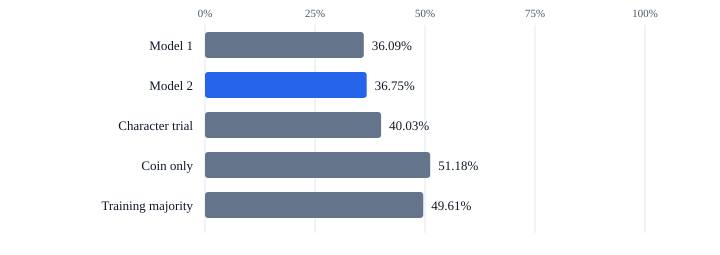

In [14]:
table(results_table(report),"Complete measured comparison")
accuracy_chart({"primary_model":"Model 2","metrics":report["tests"]["later_time"]},["Model 1","Model 2","Character trial","Coin only","Training majority"])
print("Paired date-block accuracy differences vs coin-only:",report["paired_accuracy_vs_coin_only"])

### Our findings, in plain English
Later dates: established coins: the balanced model was correct 36.75% of the time versus 51.18% without post wording or sentiment. New coins: excluded from training: the balanced model was correct 43.83% of the time versus 55.84% without post wording or sentiment. Neither result justifies following the crowd or trading on the model alone. The tested posts did not add useful direction information in this experiment; that does not prove all social information is useless. We have not measured profits or established that posts cause price movements.

## 11. Limitations and next steps
- This is a sparse archive, not every public post about a coin. Estimated sample sentiment is not validated full-population sentiment.
- The later-time and unseen-coin experiments use actual prices but reused dates; they are exploratory, not independent confirmation. Small per-coin samples limit conclusions.
- Balanced weights may increase UP recall while worsening false alarms or accuracy. They do not create trading skill. The character trial can overfit and gives less readable fragments.
- Probabilities are not independently calibrated. No profitability, fees/slippage, causal effect or useful return-magnitude forecast is established. Do not invert a losing model after seeing test labels and call that a new validated strategy.
- Next: gather a genuinely new timestamped public sample, freeze this protocol and evaluate prospectively; test whether users understand the evidence warnings.

**Investor boundary:** this prototype does not justify trading because a batch sounds bullish or the model predicts UP. Its useful result is demonstrating how apparent text-based confidence can fail a fair future-market test.

In [15]:
for filename in ["test_crowd_snapshot.py","test_sample_pipeline.py","test_crowd_app.py","test_judge_tables.py"]:
    completed=subprocess.run([sys.executable,filename],text=True,stdout=subprocess.PIPE,stderr=subprocess.STDOUT)
    print(completed.stdout);completed.check_returncode()
print("Saved safe JSON models and genuine outputs. Actual Google Colab runtime:",IN_COLAB)

.............
----------------------------------------------------------------------
Ran 13 tests in 0.001s

OK

..........
----------------------------------------------------------------------
Ran 10 tests in 32.007s

OK

..
----------------------------------------------------------------------
Ran 2 tests in 23.433s

OK

......
----------------------------------------------------------------------
Ran 6 tests in 0.015s

OK

Saved safe JSON models and genuine outputs. Actual Google Colab runtime: False


## Sources
- [financial-tweets-crypto](https://huggingface.co/datasets/StephanAkkerman/financial-tweets-crypto), pinned revision and source hash in pipeline.py.
- [FinTwitBERT sentiment](https://huggingface.co/StephanAkkerman/FinTwitBERT-sentiment), pinned safe weights; scores are model estimates, not human gold labels.
- Actual Binance spot daily bars, frozen and hash-checked. [Market-data documentation](https://github.com/binance/binance-spot-api-docs/blob/master/rest-api.md#klinecandlestick-data).
- scikit-learn, PyTorch, Transformers, safetensors, NumPy, pandas, PyArrow, IPython and ipywidgets.
- Veritas AI participant reference notebook (ScamCheck) and Finance brief, credited as methodological sources.
- Hermes Agent/OpenAI coding assistance. The team must understand and explain the work. Third-party data/model terms remain applicable.

*This project is a prototype and is not financial advice.*